In [ ]:
import pandas as pd

df = pd.read_csv('student-por.csv')

# Rows & Columns
print("=== ROWS & COLUMNS ===")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

# Data Types
print("\n=== COLUMN NAMES & DATA TYPES ===")
print(df.dtypes)

# Missing Values
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

# Duplicates
print("\n=== DUPLICATE ROWS ===")
print(f"Duplicates: {df.duplicated().sum()}")

# Numerical vs Categorocal
print("\n=== NUMERICAL vs CATEGORICAL ===")
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(f"Numerical: {num_cols}")
print(f"Categorical: {cat_cols}")

=== ROWS & COLUMNS ===
Rows: 649
Columns: 33

=== COLUMN NAMES & DATA TYPES ===
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

=== MISSING VALUES ===
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian     

In [ ]:
# Data Preprocessing

# 1. convert Categorical columns to numbers
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
cat_cols = df.select_dtypes(include='object').columns.tolist()

for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print("=== CATEGORICAL COLUMNS CONVERTED ===")
print(df.dtypes)

# 2. Target Variable from G3
df['target'] = df['G3'].apply(lambda x: 1 if x >= 10 else 0)

print("\n=== TARGET VARIABLE (Pass=1, Fail=0) ===")
print(df['target'].value_counts())

# 3. Dataset clean check
print("\n=== FINAL DATASET SHAPE ===")
print(df.shape)

print("\n=== FIRST 5 ROWS ===")
print(df.head())

=== CATEGORICAL COLUMNS CONVERTED ===
school        int64
sex           int64
age           int64
address       int64
famsize       int64
Pstatus       int64
Medu          int64
Fedu          int64
Mjob          int64
Fjob          int64
reason        int64
guardian      int64
traveltime    int64
studytime     int64
failures      int64
schoolsup     int64
famsup        int64
paid          int64
activities    int64
nursery       int64
higher        int64
internet      int64
romantic      int64
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

=== TARGET VARIABLE (Pass=1, Fail=0) ===
target
1    549
0    100
Name: count, dtype: int64

=== FINAL DATASET SHAPE ===
(649, 34)

=== FIRST 5 ROWS ===
   school  sex  age  address  famsize  Pstatus  Medu  Fedu  Mjob  Fjob  ...  \
0       0    0   18        1        0        0     4   

In [ ]:
# Feature Selection

# Input features
X = df[['studytime', 'failures', 'absences', 'G1', 'G2']]

# Output / Target
y = df['target']

print("=== SELECTED FEATURES ===")
print(X.head())

print("\n=== TARGET VARIABLE ===")
print(y.head())

print("\n=== FEATURE SHAPE ===")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

=== SELECTED FEATURES ===
   studytime  failures  absences  G1  G2
0          2         0         4   0  11
1          2         0         2   9  11
2          2         0         6  12  13
3          3         0         0  14  14
4          2         0         0  11  13

=== TARGET VARIABLE ===
0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

=== FEATURE SHAPE ===
X shape: (649, 5)
y shape: (649,)


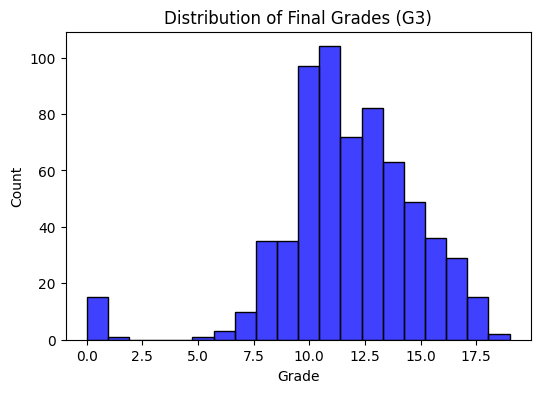

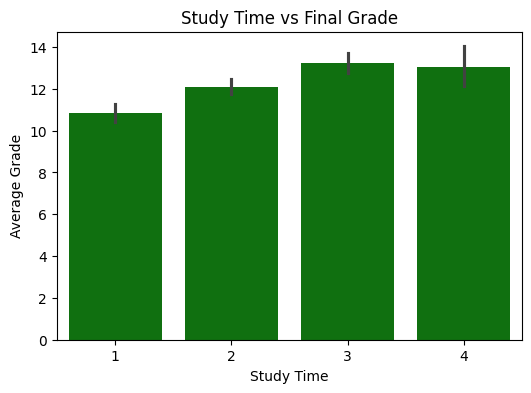

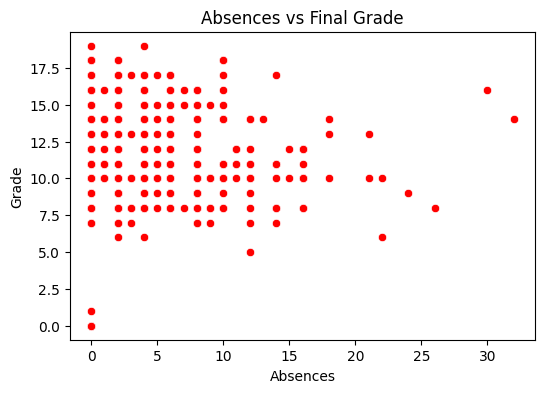

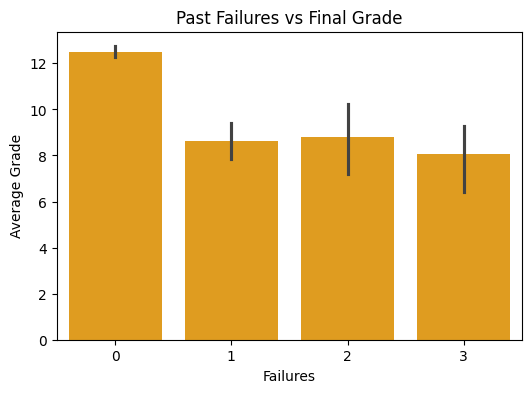

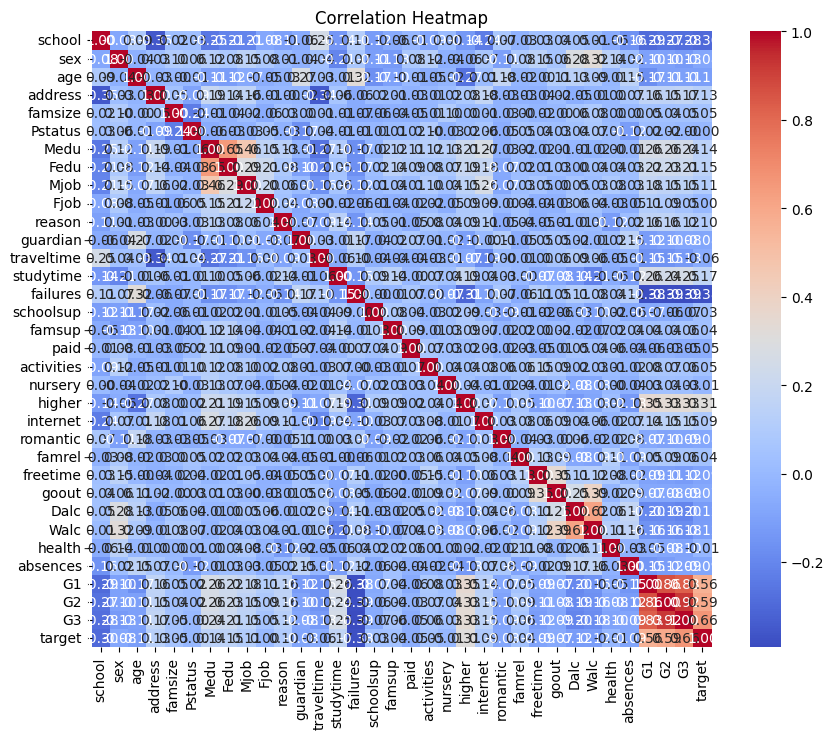

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. G3 Distribution
plt.figure(figsize=(6,4))
sns.histplot(df['G3'], bins=20, color='blue')
plt.title('Distribution of Final Grades (G3)')
plt.xlabel('Grade')
plt.ylabel('Count')
plt.show()

# 2. Study Time vs Performance
plt.figure(figsize=(6,4))
sns.barplot(x='studytime', y='G3', data=df, color='green')
plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Average Grade')
plt.show()

# 3. Absences vs Grade
plt.figure(figsize=(6,4))
sns.scatterplot(x='absences', y='G3', data=df, color='red')
plt.title('Absences vs Final Grade')
plt.xlabel('Absences')
plt.ylabel('Grade')
plt.show()

# 4. Failures vs Grade
plt.figure(figsize=(6,4))
sns.barplot(x='failures', y='G3', data=df, color='orange')
plt.title('Past Failures vs Final Grade')
plt.xlabel('Failures')
plt.ylabel('Average Grade')
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# splitting Data
X_train, X_test, y_train, y_test = train_test_split(X, df['G3'], test_size=0.2, random_state=42)

# making model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Prediction
y_pred = lr.predict(X_test)

# Results
print("=== LINEAR REGRESSION RESULTS ===")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")

=== LINEAR REGRESSION RESULTS ===
MAE: 0.75
MSE: 1.33


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# spkitting data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# making model
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

# Prediction
y_pred_class = log_reg.predict(X_test)

# Confusion Matrix
print("=== CONFUSION MATRIX ===")
print(confusion_matrix(y_test, y_pred_class))

# Detailed Report
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_class))

=== CONFUSION MATRIX ===
[[ 11   4]
 [  5 110]]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.69      0.73      0.71        15
           1       0.96      0.96      0.96       115

    accuracy                           0.93       130
   macro avg       0.83      0.84      0.84       130
weighted avg       0.93      0.93      0.93       130



In [ ]:
import numpy as np

# High study time = 3 ya 4
high_study = df[df['studytime'] >= 3]
low_study = df[df['studytime'] < 3]

# P(Pass | High Study Time)
p_pass_high_study = len(high_study[high_study['target'] == 1]) / len(high_study)

# P(Pass | Low Study Time)
p_pass_low_study = len(low_study[low_study['target'] == 1]) / len(low_study)

# P(Pass | No Failures)
no_fail = df[df['failures'] == 0]
p_pass_no_failure = len(no_fail[no_fail['target'] == 1]) / len(no_fail)

# P(Pass | Has Failures)
has_fail = df[df['failures'] > 0]
p_pass_has_failure = len(has_fail[has_fail['target'] == 1]) / len(has_fail)

print("=== BAYESIAN PROBABILITY RESULTS ===")
print(f"P(Pass | High Study Time): {p_pass_high_study:.2f}")
print(f"P(Pass | Low Study Time):  {p_pass_low_study:.2f}")
print(f"P(Pass | No Failures):     {p_pass_no_failure:.2f}")
print(f"P(Pass | Has Failures):    {p_pass_has_failure:.2f}")

=== BAYESIAN PROBABILITY RESULTS ===
P(Pass | High Study Time): 0.93
P(Pass | Low Study Time):  0.82
P(Pass | No Failures):     0.91
P(Pass | Has Failures):    0.51


In [ ]:
# Prediction System

# take input from user
print("=== STUDENT GRADE PREDICTION SYSTEM ===")
studytime = int(input("Study Time (1-4): "))
failures = int(input("Past Failures (0-3): "))
absences = int(input("Absences: "))
g1 = int(input("G1 Grade: "))
g2 = int(input("G2 Grade: "))

# make input array
user_input = [[studytime, failures, absences, g1, g2]]

# Linear Regression se Grade prediction
predicted_grade = lr.predict(user_input)[0]

#  Pass/Fail prediction by Logistic Regression
predicted_class = log_reg.predict(user_input)[0]
result = "PASS" if predicted_class == 1 else "FAIL"

print("\n=== RESULTS ===")
print(f"Predicted Grade: {predicted_grade:.1f}")
print(f"Pass/Fail Status: {result}")

=== STUDENT GRADE PREDICTION SYSTEM ===
Study Time (1-4): 3
Past Failures (0-3): 1
Absences: 3
G1 Grade: 50
G2 Grade: 67

=== RESULTS ===
Predicted Grade: 67.3
Pass/Fail Status: PASS ✅


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
